

# Lab 2: Exploring Multi-Qubit Gates

Welcome to Lab 2! In our previous labs, we focused on manipulating individual qubits. Now, it's time to explore one of the most powerful features of quantum computing: the interaction between qubits. In this notebook, we will dive into the world of multi-qubit gates, which allow us to perform conditional logic and create fascinating quantum phenomena like entanglement.

We will cover the following key topics:
*   Building and visualizing circuits with multiple qubits.
*   Applying fundamental two-qubit controlled gates:
    *   The **Controlled-NOT (CNOT or CX)** gate to create entanglement.
    *   The **Controlled-Z (CZ)** gate.
    *   The **Controlled-Hadamard (CH)** gate.
*   Implementing the **SWAP gate** to exchange the states of two qubits.
*   Creating and observing a classic entangled state: the Bell state.
*   Simulating our multi-qubit circuits to analyze their behavior using:
    1.  **Statevector Simulation:** To see the combined state of our multi-qubit system.
    2.  **Unitary Simulation:** To see the larger matrix representations of these new gates.
    3.  **Measurement Simulation (`qasm_simulator`):** To observe the correlated outcomes that arise from entanglement.

This lab is a crucial step towards understanding how complex quantum algorithms are built. Let's dive in

In [ ]:
%pip install qiskit qiskit-aer matplotlib
%pip install pylatexenc



## 1. Setting Up Our Environment and Importing Libraries

Before we start building circuits, we need to import all the necessary tools from Qiskit and other helpful Python libraries. This code block sets up our entire environment for this lab.

*   **`qiskit`:** The main library itself. We often import it to check the version.
*   **`QuantumCircuit`:** The fundamental object for creating a quantum circuit, which holds our qubits and gates.
*   **`transpile`:** A function used to optimize our quantum circuits for a specific backend (like a simulator or real hardware).
*   **`qiskit_aer` (`AerSimulator`, `Aer`):** Qiskit's high-performance simulator library. We will use `AerSimulator` to run our circuits and get results.
*   **`qiskit.visualization`:** This is Qiskit's powerful toolkit for visualizing our results. For this lab, we've imported:
    *   `plot_bloch_multivector`: To visualize the state of each individual qubit on its own Bloch sphere. This is essential for multi-qubit systems.
    *   `plot_state_qsphere` and `plot_state_city`: These are excellent for visualizing the *entire* statevector of a multi-qubit system, helping us see correlations and entanglement.
    *   `plot_histogram`: To view the final measurement outcomes after a simulation.
*   **`math` and `numpy`:** Standard Python libraries for mathematical functions (`pi`, `sqrt`) and numerical operations, which are often useful when working with quantum states.
*   **`matplotlib`:** The underlying plotting engine for many of Qiskit's visualizations.

In [ ]:
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator, Aer
from qiskit.visualization import plot_histogram
import matplotlib
from math import pi, sqrt # pi = 3.14 and square root operation
from qiskit.visualization import plot_state_city # Density Matrix plot
from qiskit.visualization import plot_state_qsphere # used for multi qubit visualisation
from qiskit.visualization import plot_bloch_multivector # Plotting the Bloch Sphere for Single Qubits
from qiskit.visualization import plot_histogram # 2D Histogram Plotting
import numpy as np # Numerical Python Library

#### Basic Qiskit Information

- **All qubits in Qiskit starts from the state |0> by default**
- **Qiskit uses little endian ordering system for both classical bit and quantum bit ordering. This means that for 3 qubits $q_0$, $q_1$ & $q_2$, the qiskit ordering is reversed as $q_2$, $q_1$ & $q_0$. Same is for classical bits as well.**

## Quantum CNOT/CX Gate

### 1. Circuit Construction and Visualization

First, we construct the quantum circuit. We use `X` gates to set the initial state to |11⟩ and then apply the `CX` gate.

- **`qc_cx = QuantumCircuit(2)`**: Creates a circuit with two qubits.
- **`qc_cx.x(0)` & `qc_cx.x(1)`**: Flips both qubits from |0⟩ to |1⟩, preparing the state |11⟩.
- **`qc_cx.cx(0,1)`**: Applies the CNOT gate. The first argument (`0`) is the control qubit, and the second (`1`) is the target.
- **`qc_cx.draw('mpl')`**: Renders a clear plot of the circuit.

In [ ]:
%pip install --upgrade pylatexenc

In [ ]:
import sys
import pylatexenc
import qiskit

print("Python:", sys.executable)
print("Qiskit:", qiskit.__version__)
print("Pylatexenc:", pylatexenc.__file__)

Python: /usr/bin/python3
Qiskit: 2.6.2
Pylatexenc: /usr/local/lib/python3.13/dist-packages/pylatexenc/__init__.py


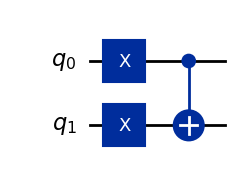

In [ ]:
!pip install pylatexenc
# CX-gate on |11> = |10> (|01> according to Qiskit ordering)
qc_cx = QuantumCircuit(2,name="qc")
qc_cx.x(0) # X Gate on 1st Qubit
qc_cx.x(1) # X Gate on 2nd Qubit
qc_cx.cx(0,1) # CX Gate with 1st Qubit as Control and 2nd Qubit as Target
qc_cx.draw('mpl')

### 2. Statevector Simulation & Density Matrix Plot

To see the pure quantum state of the circuit *before* measurement, we use the `statevector_simulator`. This gives us the final statevector, a complex vector representing the amplitudes of each basis state.

- **`Aer.get_backend('statevector_simulator')`**: Accesses the ideal simulator that calculates the final statevector.
- **`result.get_statevector()`**: Extracts the statevector `psi` from the simulation results.
- **`plot_state_city(psi)`**: Creates a "cityscape" plot of the density matrix, which is a great way to visualize the magnitude and phase of the statevector's components.

**Expected Outcome:**
The output statevector should be `[0, 0, 1, 0]`. This corresponds to the basis states |00⟩, |01⟩, |10⟩, |11⟩, respectively. A `1` in the third position means the system is deterministically in the state |10⟩. The city plot will show a single, solid blue bar at the '10' position.


Quantum state is: Statevector([0.+0.j, 1.+0.j, 0.+0.j, 0.+0.j],
            dims=(2, 2))


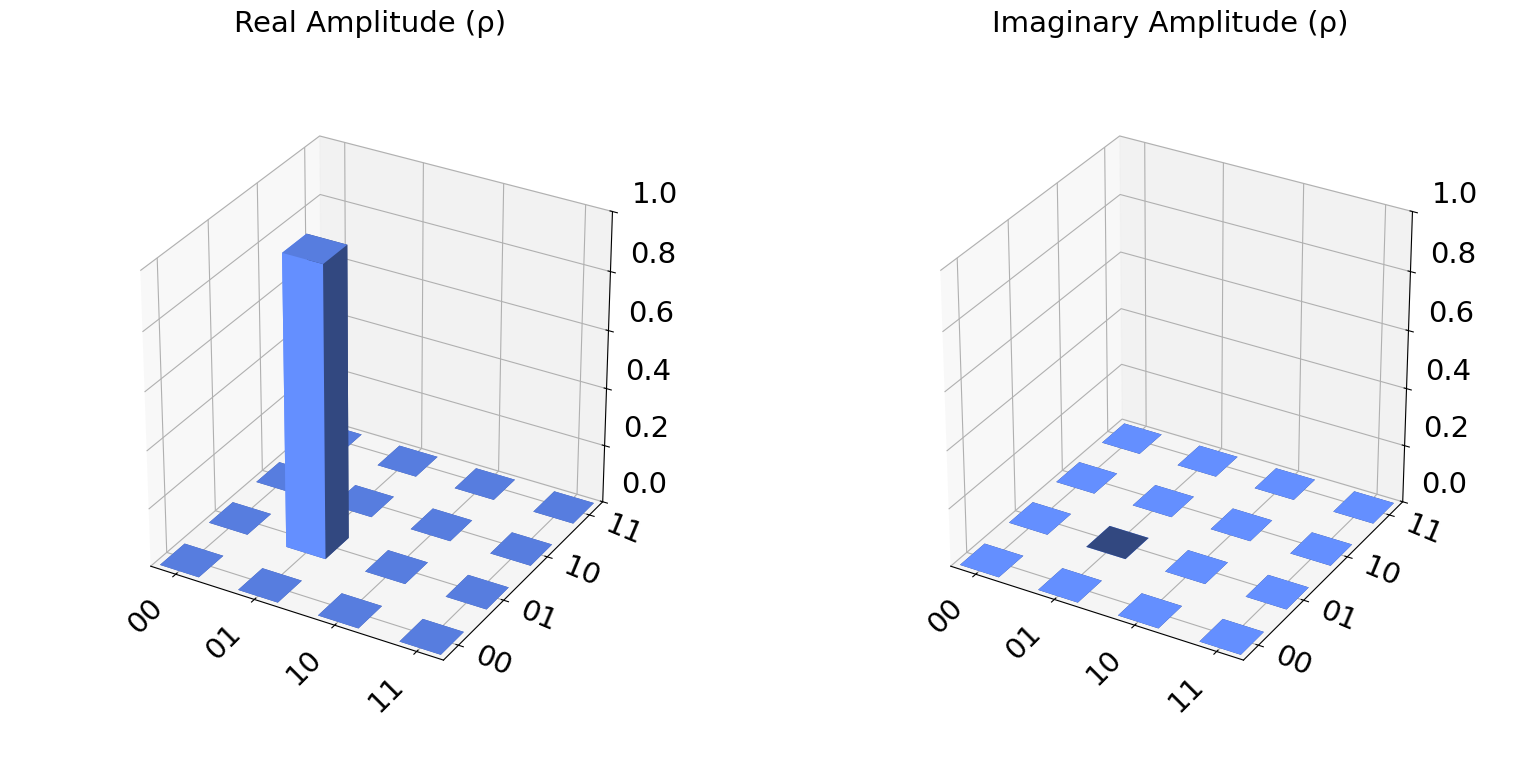

In [ ]:
simulator_state = Aer.get_backend('statevector_simulator')

job_state = transpile(qc_cx, simulator_state)

result_state = simulator_state.run(job_state).result()

psi  = result_state.get_statevector(qc_cx)
print("\nQuantum state is:",psi)

plot_state_city(psi)

### 3. Q-Sphere Visualization

The Q-sphere is another powerful tool for visualizing a multi-qubit state. It maps the amplitudes and phases of the basis states onto the surface of a sphere.

- **`plot_state_qsphere(psi)`**: Generates the Q-sphere plot from the statevector.

**Expected Outcome:**
You will see a single bright spot and a line pointing to the computational basis state corresponding to **|10⟩**, visually confirming our result. The size of the spot indicates the magnitude of the amplitude (100%), and its color represents the phase (0, or real and positive).

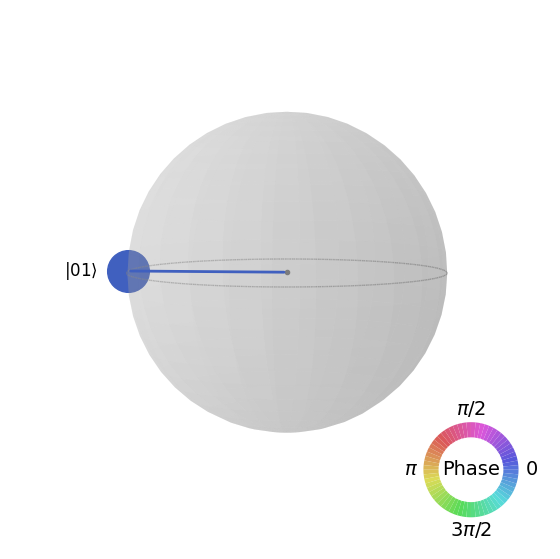

In [ ]:
# Plot the QSphere
psi  = result_state.get_statevector(qc_cx)
plot_state_qsphere(psi)

### 4. Unitary Simulation

The `unitary_simulator` calculates the 4x4 matrix that represents the *entire sequence of operations* in our circuit. This is useful for verifying the mathematical transformation performed by our gates.

**Important:** The resulting unitary matrix is for the composite operation `CX * (X ⊗ X)`, not just the CX gate alone.

**Expected Outcome:**
The simulator will output the 4x4 matrix equivalent to applying two X-gates followed by a CNOT gate. This matrix, when applied to the initial state vector for |00⟩ (which is `[1, 0, 0, 0]`), would produce the final state vector for |10⟩ (`[0, 0, 1, 0]`).

In [ ]:
backend = Aer.get_backend('unitary_simulator')

transpiled_qc = transpile(qc_cx, backend)

job = backend.run(transpiled_qc)

result = job.result()

unitary_matrix = result.get_unitary()

print("Unitary matrix of the circuit:")
print(np.round(unitary_matrix.data, 3))

Unitary matrix of the circuit:
[[0.+0.j 0.+0.j 0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]]


### 5. Measurement Simulation with `qasm_simulator`

This simulation mimics a real quantum computer. We add measurement operations to our circuit and run it for a number of "shots" to get a statistical distribution of the outcomes.

- **`QuantumCircuit(2,2)`**: Creates a circuit with 2 qubits and 2 classical bits for storing measurement results.
- **`qc_cx.measure([0,1],[0,1])`**: Measures qubit 0 and maps the result to classical bit 0; measures qubit 1 and maps it to classical bit 1.
- **`Aer.get_backend('qasm_simulator')`**: Accesses the simulator that models measurement and noise.
- **`backend.run(..., shots=1000)`**: Executes the circuit 1000 times.
- **`result.get_counts()`**: Returns a dictionary of the measurement outcomes and how many times each occurred.
- **`plot_histogram(counts)`**: Displays the results as a bar chart.

**Expected Outcome:**
Since the final state |10⟩ is a computational basis state, there is no randomness. Every single one of the 1000 shots should yield the result `'10'`. The histogram will show a single bar at `'10'` with a probability of 1.0 (or a count of 1000).

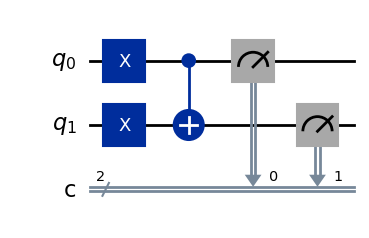

In [ ]:
# CNOT with Measurement
qc_cx = QuantumCircuit(2,2,name="qc")
qc_cx.x(0) # X Gate on 1st Qubit
qc_cx.x(1) # X Gate on 2nd Qubit
qc_cx.cx(0,1) # CX Gate with 1st Qubit as Control and 2nd Qubit as Target
qc_cx.measure([0,1],[0,1])
qc_cx.draw('mpl')


Total counts are: {'01': 1000}


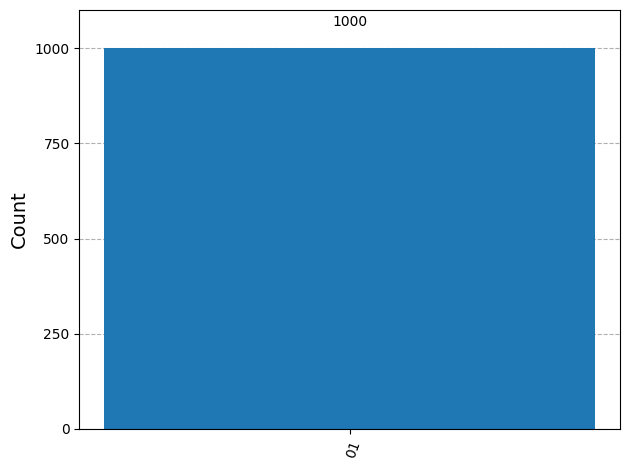

In [ ]:
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qc_cx, backend)

job = backend.run(transpiled_qc, shots=1000)

result = job.result()

counts = result.get_counts()
print("\nTotal counts are:", counts)

plot_histogram(counts)

### 6. Alternative CNOT Implementation: H-CZ-H

The CNOT gate can be constructed from other fundamental gates. A common identity is that a CX gate is equivalent to a CZ gate surrounded by Hadamard gates on the **target qubit**.

**Identity:** `CX(c, t) = (I ⊗ H_t) * CZ(c, t) * (I ⊗ H_t)`

Here, we build this equivalent circuit to demonstrate that it produces the exact same result. The `barrier()` calls are added for visual clarity in the circuit diagram and have no logical effect.

**Expected Outcome:**
The measurement results will be identical to the previous `qasm_simulator` run. The histogram will show 100% of the counts in the `'10'` state, proving that for the input |11⟩, this H-CZ-H construction is functionally identical to a native CX gate.

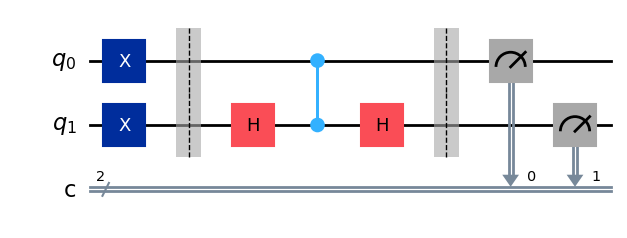

In [ ]:
# CNOT with Measurement
qc_cx = QuantumCircuit(2,2,name="qc")
qc_cx.x(0) # X Gate on 1st Qubit
qc_cx.x(1) # X Gate on 2nd Qubit
qc_cx.barrier()
qc_cx.h(1) # H Gate on 2nd Qubit
qc_cx.cz(0,1) # CZ Gate
qc_cx.h(1) # H Gate on 2nd Qubit
qc_cx.barrier()
qc_cx.measure([0,1],[0,1])
qc_cx.draw('mpl')


Total counts are: {'01': 1000}


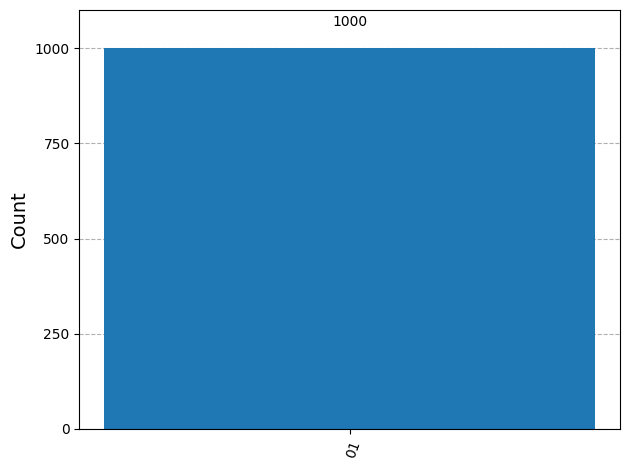

In [ ]:
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qc_cx, backend)

job = backend.run(transpiled_qc, shots=1000)

result = job.result()

counts = result.get_counts()
print("\nTotal counts are:", counts)

plot_histogram(counts)

## Quantum CZ Gate

### 1. Circuit Construction

We build a simple circuit to isolate the action of the CZ gate. First, we prepare the |11⟩ state using `X` gates, which is the only basis state that the CZ gate affects.

- **`qc_cz.x(0)` & `qc_cz.x(1)`**: Prepares the initial state |11⟩.
- **`qc_cz.cz(0,1)`**: Applies the Controlled-Z gate.

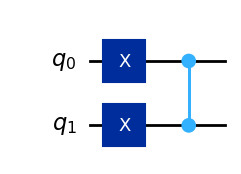

In [ ]:
# CZ-gate on |11> = -|11> (|11> according to Qiskit ordering)
qc_cz = QuantumCircuit(2,name="qc")
qc_cz.x(0) # X Gate on 1st Qubit
qc_cz.x(1) # X Gate on 2nd Qubit
qc_cz.cz(0,1) # CZ Gate with 1st Qubit as Control and 2nd Qubit as Target
qc_cz.draw('mpl')

### 2. Statevector Simulation & Density Matrix Plot

Using the `statevector_simulator` allows us to see the pure quantum state, including its phase information.

- **`result.get_statevector()`**: Extracts the final statevector `psi`.
- **`plot_state_city(psi)`**: Visualizes the density matrix. The height of a bar represents the probability of a state, and its **color represents its phase**.

**Expected Outcome:**
The output statevector will be `[0, 0, 0, -1]`, corresponding to the state -|11⟩. In the city plot, you will see a single bar at the `'11'` position. Unlike previous plots, this bar will be colored differently (e.g., red instead of blue) to indicate a phase of π (which is equivalent to a factor of -1).


Quantum state is: Statevector([ 0.+0.j,  0.+0.j,  0.+0.j, -1.+0.j],
            dims=(2, 2))


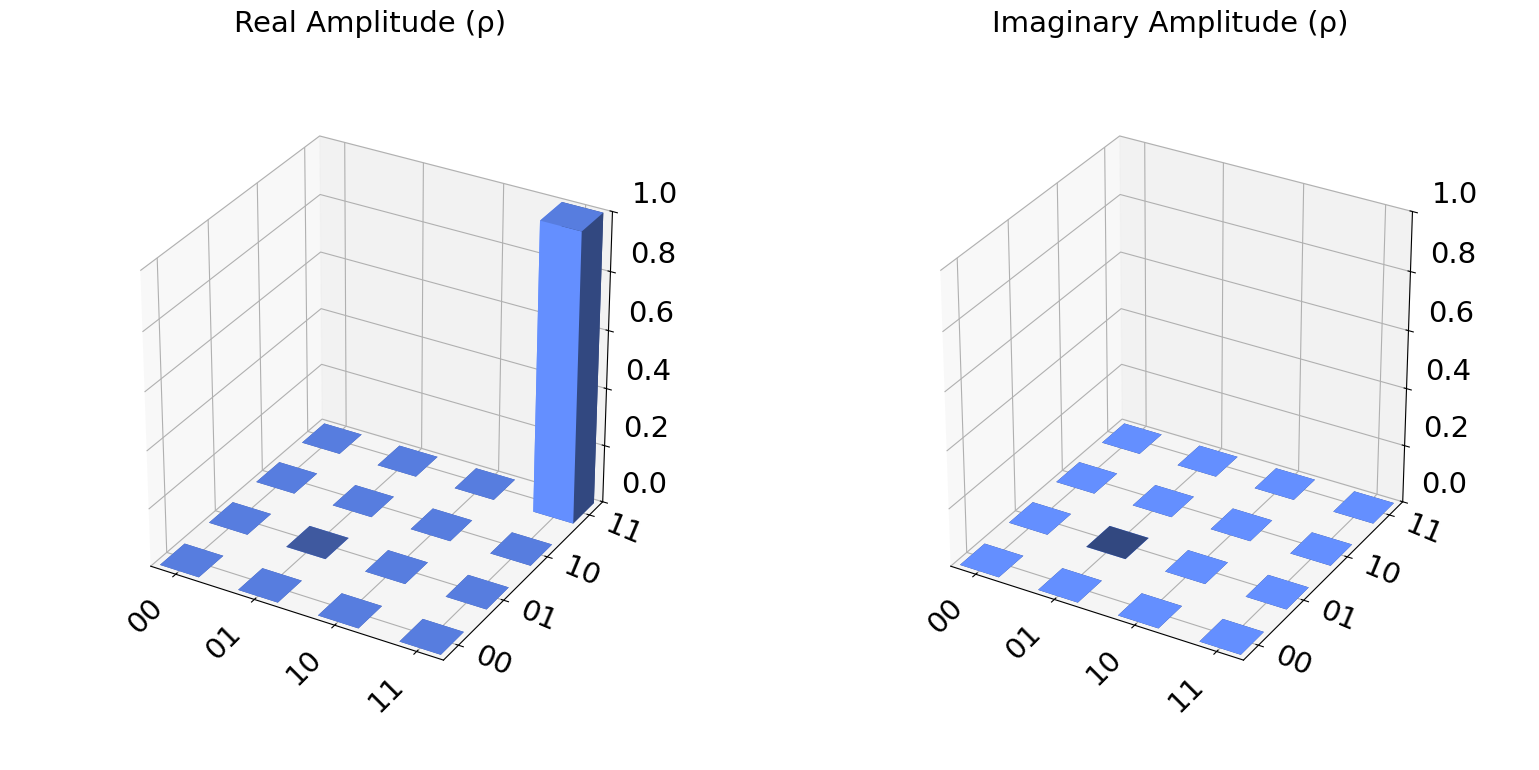

In [ ]:
simulator_state = Aer.get_backend('statevector_simulator')

transpiled_qc = transpile(qc_cz, simulator_state)

job_state = simulator_state.run(transpiled_qc)

result_state = job_state.result()

psi  = result_state.get_statevector()
print("\nQuantum state is:", psi)

plot_state_city(psi)

### 3. Q-Sphere Visualization

The Q-sphere provides another view of the statevector, where color is again used to represent phase.

- **`plot_state_qsphere(psi)`**: Generates the Q-sphere plot.

**Expected Outcome:**
The plot will show a single bright spot at the computational basis state **|11⟩**. The color of this spot will not be the default blue/cyan but will instead be a color that represents the negative phase, visually confirming the action of the CZ gate.

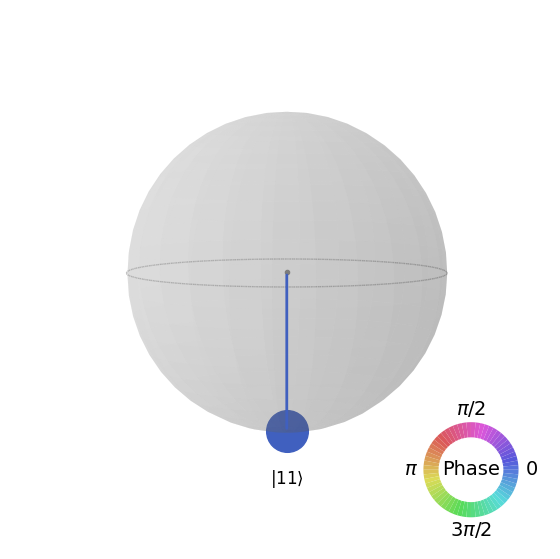

In [ ]:
# Plot the QSphere
psi  = result_state.get_statevector(qc_cz)
plot_state_qsphere(psi)

### 4. Unitary Simulation

The `unitary_simulator` computes the matrix representation for the entire circuit. This shows the mathematical transformation from the initial |00⟩ state to the final -|11⟩ state.

**Note:** The resulting matrix is for the composite operation `CZ * (X ⊗ X)`.

**Expected Outcome:**
The simulator will output the 4x4 matrix for the circuit. The matrix for a bare CZ gate is `diag(1, 1, 1, -1)`. The output here will be the result of that matrix multiplied by the matrix for the two preceding X gates.

In [ ]:
backend = Aer.get_backend('unitary_simulator')

transpiled_qc = transpile(qc_cz, backend)

job = backend.run(transpiled_qc)

result = job.result()

unitary_matrix = result.get_unitary()

print("Unitary matrix of the circuit:")
print(np.round(unitary_matrix.data, 3))

Unitary matrix of the circuit:
[[ 0.+0.j  0.+0.j  0.+0.j  1.+0.j]
 [ 0.+0.j  0.+0.j  1.+0.j  0.+0.j]
 [ 0.+0.j  1.+0.j  0.+0.j  0.+0.j]
 [-1.+0.j -0.+0.j -0.+0.j -0.+0.j]]


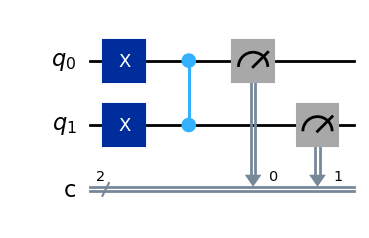

In [ ]:
# CZ-gate with measurement
qc_cz = QuantumCircuit(2,2,name="qc")
qc_cz.x(0) # X Gate on 1st Qubit
qc_cz.x(1) # X Gate on 2nd Qubit
qc_cz.cz(0,1) # CZ Gate with 1st Qubit as Control and 2nd Qubit as Target
qc_cz.measure([0,1],[0,1])
qc_cz.draw('mpl')

### 5. Measurement Simulation with `qasm_simulator`

This is the most critical demonstration for the CZ gate. What happens to the phase information when we measure?

- **Measurement Rule:** The probability of measuring a state is the **square of the magnitude** of its amplitude.
- **For state |11⟩:** The amplitude is 1. Probability = |1|² = 1.
- **For state -|11⟩:** The amplitude is -1. Probability = |-1|² = 1.

The phase is lost upon measurement. We cannot distinguish between |11⟩ and -|11⟩ by measuring in the Z-basis.

**Expected Outcome:**
Every single one of the 1000 shots will yield the result `'11'`. The histogram will show a single bar at `'11'` with a probability of 1.0. This demonstrates that while the underlying quantum state has changed (it gained a negative phase), the measurement statistics in this basis are identical to a circuit without the CZ gate.


Total counts are: {'11': 1000}


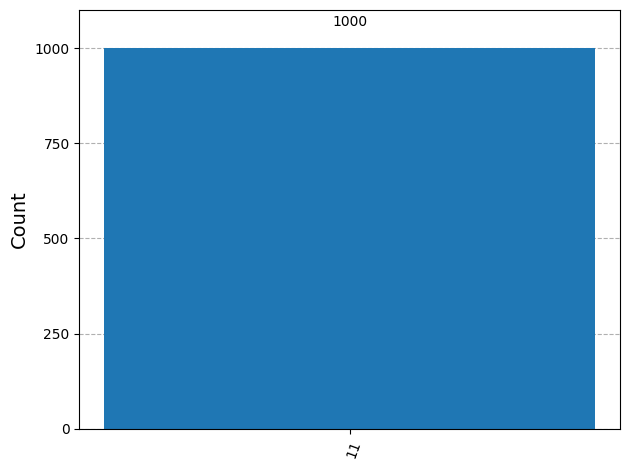

In [ ]:
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qc_cz, backend)

job = backend.run(transpiled_qc, shots=1000)

result = job.result()

counts = result.get_counts()
print("\nTotal counts are:", counts)

plot_histogram(counts)

### 6. Alternative CZ Implementation: H-CX-H

Just as CX can be built from CZ, CZ can be built from CX. The identity is that a CZ gate is equivalent to a CX gate surrounded by Hadamard gates on the **target qubit**.

**Identity:** `CZ(c, t) = (I ⊗ H_t) * CX(c, t) * (I ⊗ H_t)`

This circuit is constructed to prove this equivalence.

**Expected Outcome:**
The measurement results will be identical to the native CZ circuit. The histogram will show 100% of the counts in the `'11'` state, confirming that this H-CX-H construction is a valid implementation of the CZ gate.

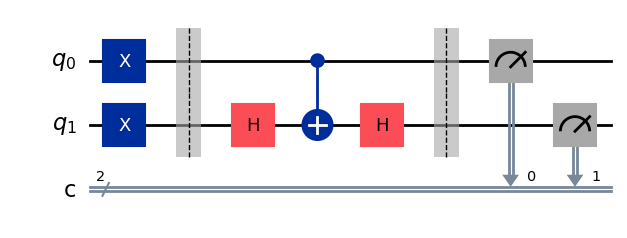

In [ ]:
# CZ-gate with measurement
qc_cz = QuantumCircuit(2,2,name="qc")
qc_cz.x(0) # X Gate on 1st Qubit
qc_cz.x(1) # X Gate on 2nd Qubit
qc_cz.barrier()
qc_cz.h(1) # H Gate on 2nd Qubit
qc_cz.cx(0,1) # CNOT Gate
qc_cz.h(1) # H Gate on 2nd Qubit
qc_cz.barrier()
qc_cz.measure([0,1],[0,1])
qc_cz.draw('mpl')


Total counts are: {'11': 1000}


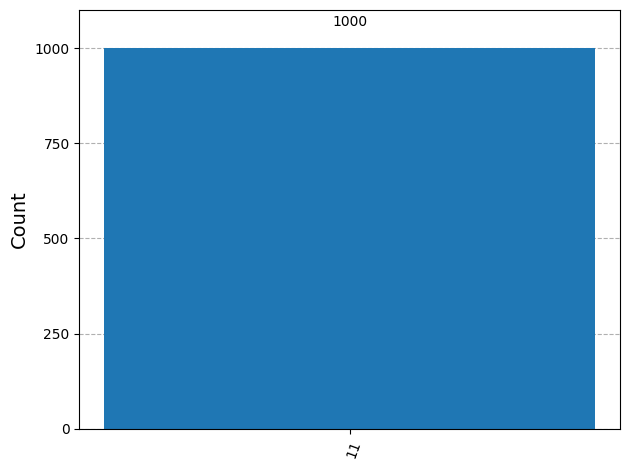

In [ ]:
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qc_cz, backend)

job = backend.run(transpiled_qc, shots=1000)

result = job.result()

counts = result.get_counts()
print("\nTotal counts are:", counts)

plot_histogram(counts)

## Quantum CH Gate

### 1. Circuit Construction

We build a circuit to apply the CH gate to the |11⟩ state.

- **`qc_ch.x(0)` & `qc_ch.x(1)`**: Prepares the initial state |11⟩.
- **`qc_ch.ch(0,1)`**: Applies the Controlled-Hadamard gate, with q0 as control and q1 as target.

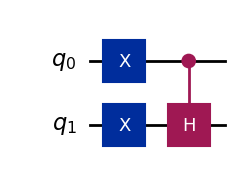

In [ ]:
# CH-gate on |11>
qc_ch = QuantumCircuit(2,name="qc")
qc_ch.x(0) # X Gate on 1st Qubit
qc_ch.x(1) # X Gate on 2nd Qubit
qc_ch.ch(0,1) # CH Gate with 1st Qubit as Control and 2nd Qubit as Target
qc_ch.draw('mpl')

### 2. Statevector Simulation & Density Matrix Plot

We use the `statevector_simulator` to see the exact final state, including the superposition and phase information.

- **`result.get_statevector()`**: Extracts the statevector `psi`.
- **`plot_state_city(psi)`**: Visualizes the statevector.

**Expected Outcome:**
The output statevector should be `[0, 0, 1/√2, -1/√2]`, which is approximately `[0, 0, 0.707, -0.707]`. The city plot will show two bars of equal height (representing equal probability) at the `'10'` and `'11'` positions. The bars will be colored differently to indicate that one has a positive phase (for |10⟩) and the other has a negative phase (for |11⟩).


Quantum state is: Statevector([-1.92280870e-32+1.23259516e-32j,
              7.07106781e-01-2.70720689e-16j,
              5.01701080e-32+6.12323400e-17j,
             -7.07106781e-01+6.89446633e-16j],
            dims=(2, 2))


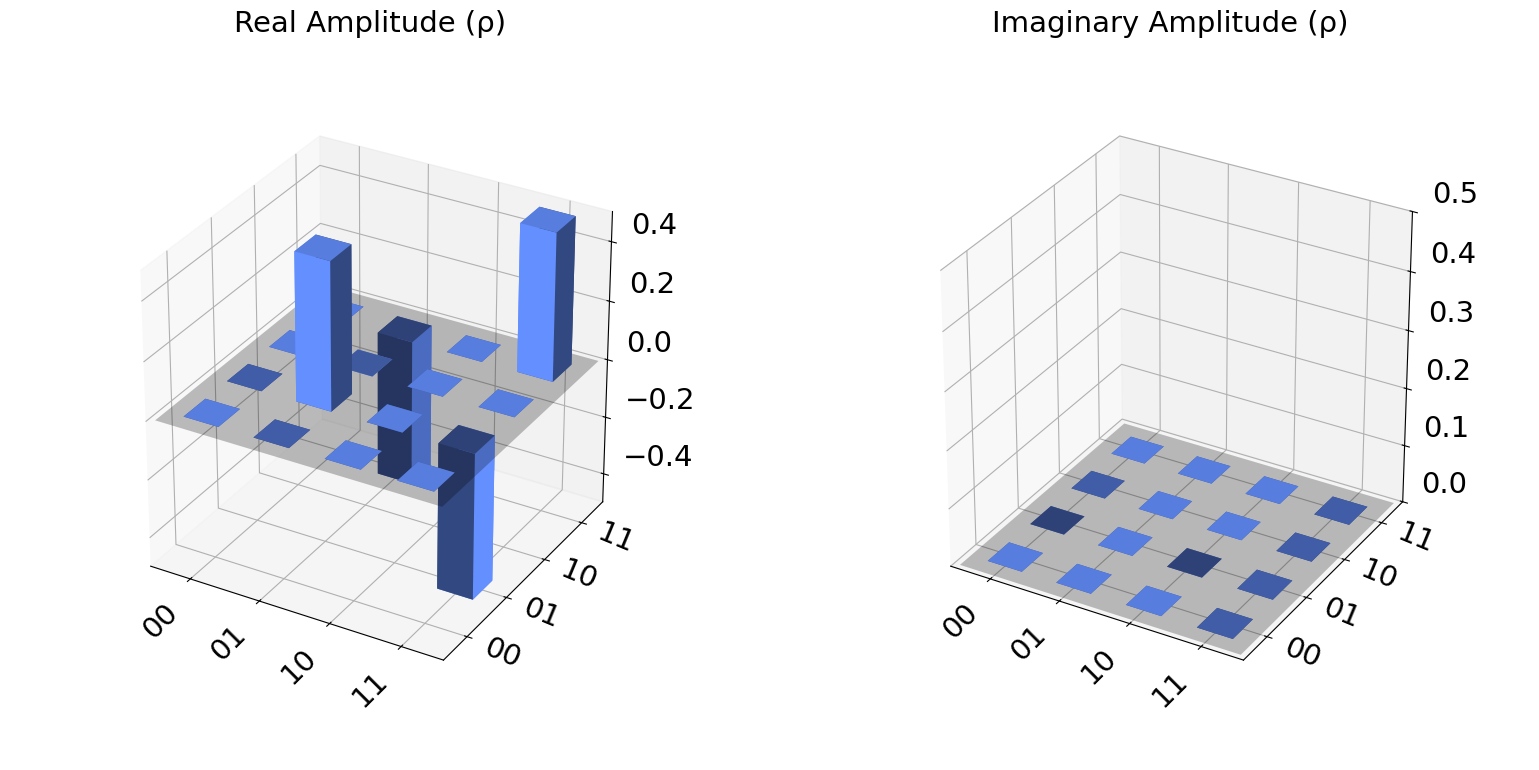

In [ ]:
simulator_state = Aer.get_backend('statevector_simulator')

transpiled_qc = transpile(qc_ch, simulator_state)

job_state = simulator_state.run(transpiled_qc)

result_state = job_state.result()

psi  = result_state.get_statevector()
print("\nQuantum state is:", psi)

plot_state_city(psi)

### 3. Q-Sphere Visualization

The Q-sphere plot gives a multi-qubit overview of the state.

- **`plot_state_qsphere(psi)`**: Generates the plot.

**Expected Outcome:**
The Q-sphere will show two bright spots of equal size at the locations corresponding to **|10⟩** and **|11⟩**. Their different colors will visually confirm the phase difference between the two components of the superposition.

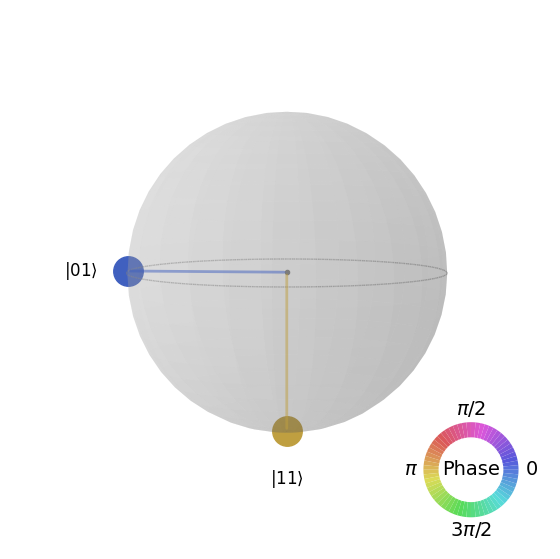

In [ ]:
# Plot the QSphere
psi  = result_state.get_statevector(qc_ch)
plot_state_qsphere(psi)

### 4. Unitary Simulation

The `unitary_simulator` calculates the matrix for the entire sequence of operations in the circuit.

**Note:** The resulting matrix represents the composite operation `CH * (X ⊗ X)`.

**Expected Outcome:**
The simulator will output the 4x4 unitary matrix for the full circuit. Applying this matrix to the initial state vector for |00⟩ would produce the final state vector for (|10⟩ - |11⟩)/√2.

In [ ]:
backend = Aer.get_backend('unitary_simulator')

transpiled_qc = transpile(qc_ch, backend)

job = backend.run(transpiled_qc)

result = job.result()

unitary_matrix = result.get_unitary()

print("Unitary matrix of the circuit:")
print(np.round(unitary_matrix.data, 3))

Unitary matrix of the circuit:
[[-0.   +0.j  0.   +0.j  0.   +0.j  1.   -0.j]
 [ 0.707-0.j  0.   +0.j  0.707+0.j -0.   +0.j]
 [ 0.   +0.j  1.   -0.j -0.   -0.j -0.   +0.j]
 [-0.707+0.j -0.   -0.j  0.707-0.j  0.   +0.j]]


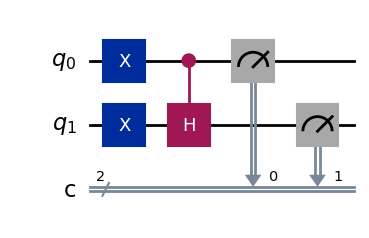

In [ ]:
# CH-gate on |11>
qc_ch = QuantumCircuit(2,2,name="qc")
qc_ch.x(0) # X Gate on 1st Qubit
qc_ch.x(1) # X Gate on 2nd Qubit
qc_ch.ch(0,1) # CH Gate with 1st Qubit as Control and 2nd Qubit as Target
qc_ch.measure([0,1],[0,1])
qc_ch.draw('mpl')

### 5. Measurement Simulation with `qasm_simulator`

When we measure the final superposition state, the outcome is probabilistic. The probability of measuring each basis state is the squared magnitude of its amplitude.

- **Probability of measuring '10'**: |1/√2|² = 1/2 = 50%
- **Probability of measuring '11'**: |-1/√2|² = 1/2 = 50%

The phase information does not affect the measurement probabilities, only the relative relationship between the states *before* measurement.

**Expected Outcome:**
After running 1000 shots, the `counts` will be split approximately evenly between `'10'` and `'11'`. The histogram will show two bars of roughly equal height at these two outcomes.


Total counts are: {'11': 499, '01': 501}


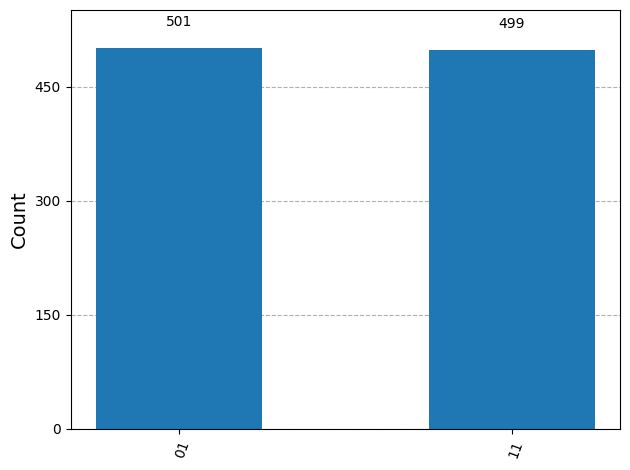

In [ ]:
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qc_ch, backend)

job = backend.run(transpiled_qc, shots=1000)

result = job.result()

counts = result.get_counts()
print("\nTotal counts are:", counts)

plot_histogram(counts)

### 6. Alternative CH Implementation

Like other controlled gates, the CH gate can be decomposed into a sequence of more fundamental gates. One such decomposition involves `Ry` (Y-rotation) gates and a `CX` gate.

**Identity:** `CH(c, t) = (I ⊗ Ry(-π/4)_t) * CX(c, t) * (I ⊗ Ry(π/4)_t)`

This circuit is constructed to verify that this decomposition is equivalent to the native `CH` gate.

**Expected Outcome:**
The measurement results will be statistically identical to the native CH circuit. The histogram will again show an approximately 50/50 split between `'10'` and `'11'`, confirming that this decomposition is a valid implementation of the CH gate.

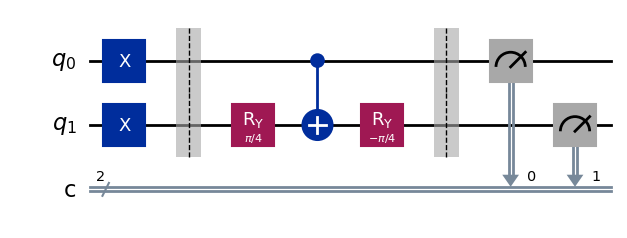

In [ ]:
# CH-gate on |11>
qc_ch = QuantumCircuit(2,2,name="qc")
qc_ch.x(0) # X Gate on 1st Qubit
qc_ch.x(1) # X Gate on 2nd Qubit
qc_ch.barrier()
qc_ch.ry(pi/4,1) # Ry Gate on 2nd Qubit
qc_ch.cx(0,1) # CNOT Gate
qc_ch.ry(-pi/4,1) # Ry Gate on 2nd Qubit
qc_ch.barrier()
qc_ch.measure([0,1],[0,1])
qc_ch.draw('mpl')


Total counts are: {'01': 508, '11': 492}


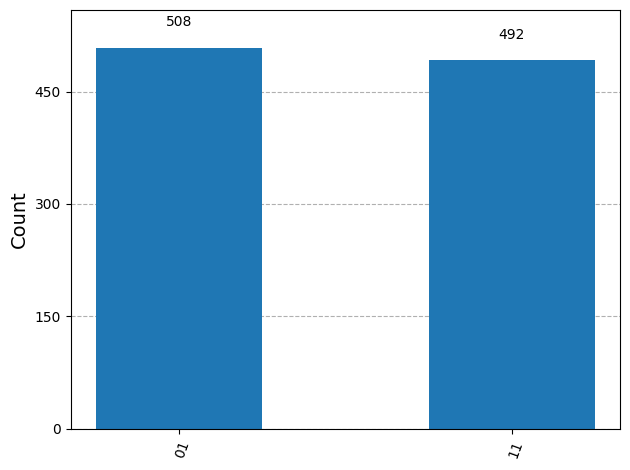

In [ ]:
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qc_ch, backend)

job = backend.run(transpiled_qc, shots=1000)

result = job.result()

counts = result.get_counts()
print("\nTotal counts are:", counts)

plot_histogram(counts)

## Quantum SWAP Gate

### 1. Circuit Construction

We build a circuit to prepare the initial state |10⟩ and then apply the SWAP gate.

- **`qc_sw.x(1)`**: Flips qubit 1 from |0⟩ to |1⟩. Since qubit 0 starts as |0⟩, the initial state of the system is |10⟩.
- **`qc_sw.swap(0,1)`**: Applies the SWAP gate, exchanging the states of the two qubits.

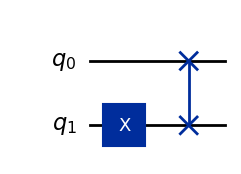

In [ ]:
# SWAP Gate on |01> = |10> (|01> in Qiskit Ordering)
qc_sw = QuantumCircuit(2,name="qc")
qc_sw.x(1) # X Gate on 2nd Qubit
qc_sw.swap(0,1) # SWAP Gate Operation
qc_sw.draw(output='mpl')

### 2. Statevector Simulation & Density Matrix Plot

We use the `statevector_simulator` to confirm that the state has been correctly swapped.

- **`result.get_statevector()`**: Extracts the statevector `psi` from the simulation.
- **`plot_state_city(psi)`**: Visualizes the statevector.

**Expected Outcome:**
The output statevector should be `[0, 1, 0, 0]`. This vector corresponds to the basis states |00⟩, |01⟩, |10⟩, |11⟩. A `1` in the second position means the system is deterministically in the state **|01⟩**. The city plot will show a single, solid blue bar at the `'01'` position, confirming the swap was successful.


Quantum state is: Statevector([0.+0.j, 0.+0.j, 1.+0.j, 0.+0.j],
            dims=(2, 2))


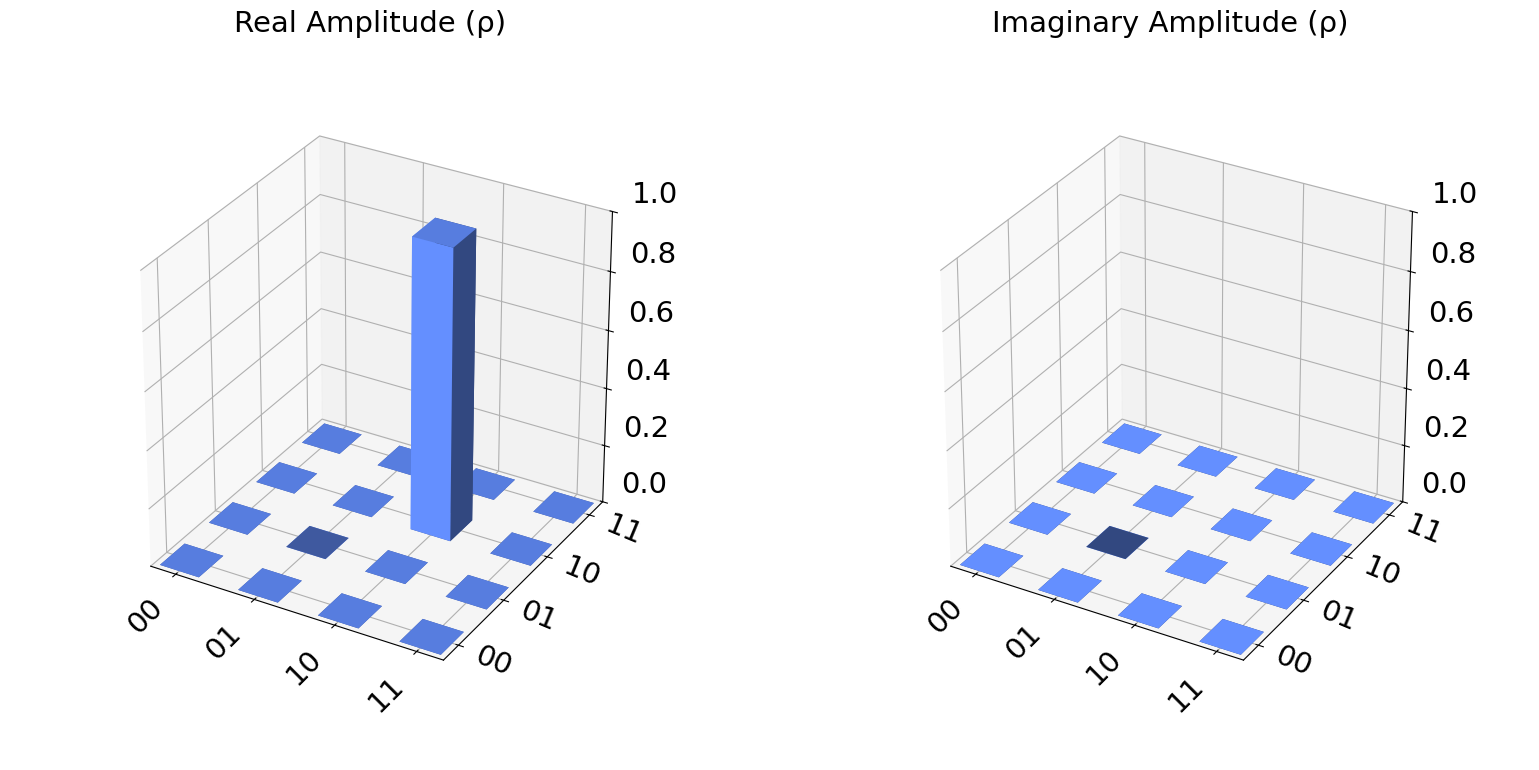

In [ ]:
simulator_state = Aer.get_backend('statevector_simulator')

transpiled_qc = transpile(qc_sw, simulator_state)

job_state = simulator_state.run(transpiled_qc)

result_state = job_state.result()

psi  = result_state.get_statevector()
print("\nQuantum state is:", psi)

plot_state_city(psi)

### 3. Q-Sphere Visualization

The Q-sphere provides a visual confirmation of the final state.

- **`plot_state_qsphere(psi)`**: Generates the Q-sphere plot.

**Expected Outcome:**
The plot will show a single bright spot with a positive (blue/cyan) phase located at the vertex corresponding to the basis state **|01⟩**.

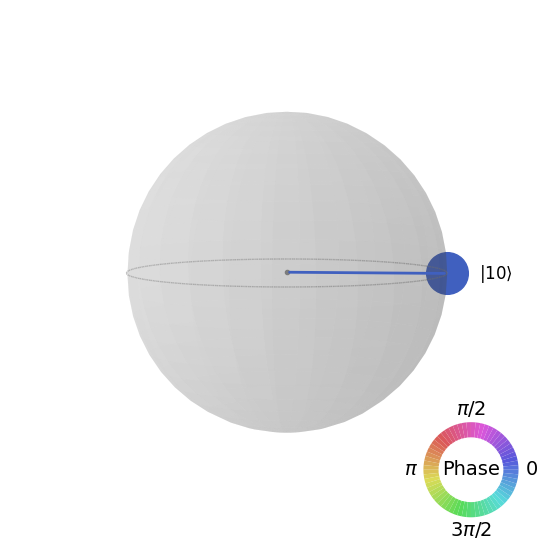

In [ ]:
# Plot the QSphere
psi  = result_state.get_statevector(qc_sw)
plot_state_qsphere(psi)

### 4. Unitary Simulation

The `unitary_simulator` computes the 4x4 matrix for the entire circuit.

**Note:** The resulting matrix represents the composite operation `SWAP * (X_1 ⊗ I_0)`. The matrix for a bare SWAP gate swaps the second and third columns (and rows) of the identity matrix, corresponding to swapping the basis states |01⟩ and |10⟩.

**Expected Outcome:**
The simulator will output the 4x4 matrix that transforms the initial state vector for |00⟩ into the final state vector for |01⟩.

In [ ]:
backend = Aer.get_backend('unitary_simulator')

transpiled_qc = transpile(qc_sw, backend)

job = backend.run(transpiled_qc)

result = job.result()

unitary_matrix = result.get_unitary()

print("Unitary matrix of the circuit:")
print(np.round(unitary_matrix.data, 3))

Unitary matrix of the circuit:
[[0.+0.j 0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]]


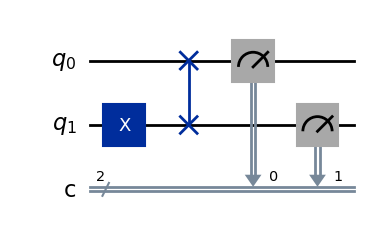

In [ ]:
# SWAP Gate on |01> = |10> (|01> in Qiskit Ordering)
qc_sw = QuantumCircuit(2,2,name="qc")
qc_sw.x(1) # X Gate on 2nd Qubit
qc_sw.swap(0,1) # SWAP Gate Operation
qc_sw.measure([0,1],[0,1])
qc_sw.draw(output='mpl')

### 5. Measurement Simulation with `qasm_simulator`

Since the final state |01⟩ is a computational basis state, there is no ambiguity in the measurement outcome. We add measurement operators and run the circuit multiple times to verify the result.

**Expected Outcome:**
Every single one of the 1000 shots will yield the measurement result `'01'`. The histogram will show a single bar at `'01'` with a probability of 1.0 (or a count of 1000), demonstrating the deterministic nature of the SWAP operation on basis states.


Total counts are: {'01': 1000}


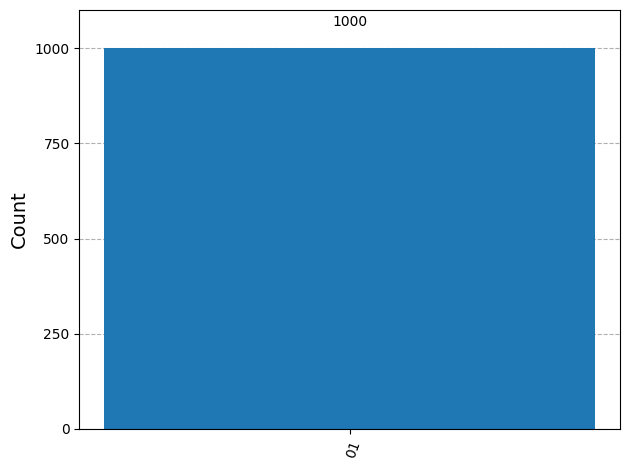

In [ ]:
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qc_sw, backend)

job = backend.run(transpiled_qc, shots=1000)

result = job.result()

counts = result.get_counts()
print("\nTotal counts are:", counts)

plot_histogram(counts)